In [1]:
from six_state_model import dynamic_steady_state_diagram
from dynamic_catalysis_model import cycle_flux_six_states
from itertools import product
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt

# Part 1: verify that spanning trees work still

In [2]:
def spanTrees(trs, Edg, all_span_trees, k):
    if k == 0:
        all_span_trees.extend(product(*trs))#Expand parallels edges using the Cartesian product
    
    for i in range(k):
        if Edg[k][i] == []: continue
        trs.append(Edg[k][i])
        Edg[i] = [Edg[i][j] + Edg[k][j] for j in range(i)]#Contraction 
        spanTrees(trs, Edg, all_span_trees, k-1)
        trs.pop()
        [Edg[i][j].pop() for j in range(i) for _ in range(len(Edg[k][j]))]#Deletion

#Helper function
def Spanning_Trees_Generator(g, hch = False):
    if not nx.is_connected(g):
        print("Only for connected graphs")
        return 0
    if nx.is_directed(g): nx.to_undirected(g)
    n = g.number_of_nodes()
    edgs = list(g.edges)
    Edg = [[[] for _ in range(n)] for _ in range(n)]
    mx = len(edgs)
    edgNum = dict() #dictionary designed to store labeled edges where the keys are integer labels for the edges, and the values are tuples representing the ordinary edge definitions (in, out)

    for ed in edgs:
        i, j = sorted(ed)
        Edg[j][i] = [mx]
        edgNum[mx] = ed
        mx -= 1
    all_span_trees = []
    spanTrees([], Edg, all_span_trees, n-1)
  
    if hch:  
        return all_span_trees #Generate only the labeled edges (Keys) 
    else:
        return [nx.Graph(edgNum[k] for k in element) for element in all_span_trees] #Generate spanning trees as NetworkX graphics objects

In [3]:
G = nx.Graph()
G.add_nodes_from([2, 1, 0, 3, 4, 5])
G.add_edges_from([(0, 1), (1, 2), (0,2), (3,4), (4,5), (3,5), (0,3), (1,4), (2,5)])
spanTreesGraph = Spanning_Trees_Generator(G)

spanTreesGraph[14] = np.nan
spanTreesGraph[17] = np.nan
spanTreesGraph[27] = np.nan
spanTreesGraph[30] = np.nan
spanTreesGraph[33] = np.nan
spanTreesGraph[58] = np.nan
spanTreesGraph[61] = np.nan
spanTreesGraph[70] = np.nan
spanTreesGraph[73] = np.nan
spanTreesGraph = [g for g in spanTreesGraph if type(g) != float]


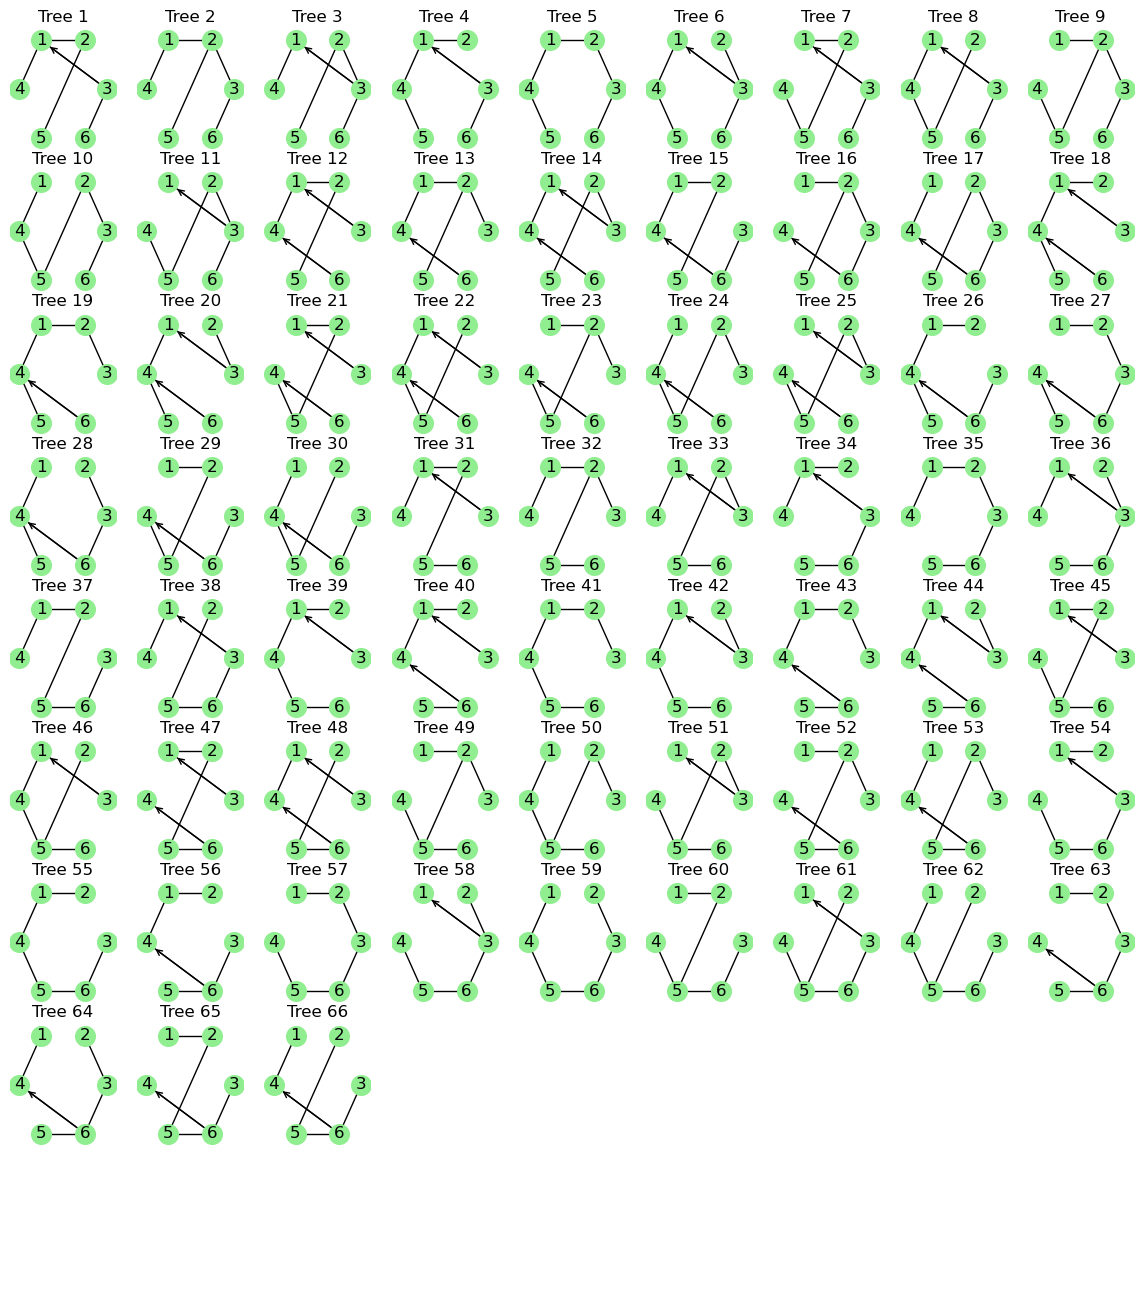

In [4]:
fig, axs = plt.subplots(9, 9, figsize=(1.8125 * 8, 1.8125 * 9))
pos = nx.circular_layout(G)

for i, g in enumerate(spanTreesGraph):
    x_ax = i // 9
    y_ax = i % 9
    if (0,2) in g.edges or (2,0) in g.edges :
        axs[x_ax][y_ax].annotate('', xy=np.array(pos[0]) + 0.1 * (np.array(pos[2]) - np.array(pos[0])), xytext=np.array(pos[2]) - 0.1 * (np.array(pos[2]) - np.array(pos[0])), \
                                 arrowprops=dict(arrowstyle='->'))
    if (3,5) in g.edges or (5,3) in g.edges:
        axs[x_ax][y_ax].annotate('', xy=np.array(pos[3]) + 0.1 * (np.array(pos[5]) - np.array(pos[3])), xytext=np.array(pos[5]) - 0.1 * (np.array(pos[5]) - np.array(pos[3])), \
                                 arrowprops=dict(arrowstyle='->'))
    axs[x_ax][y_ax].set_title(f"Tree {i+1}")
    nx.draw(g, pos, labels = {n: n+1 for n in G}, node_color='lightgreen', node_size=200, ax=axs[x_ax][y_ax])

for i in range(9):
    for j in range(9):
        axs[i][j].axis('off')
plt.show()


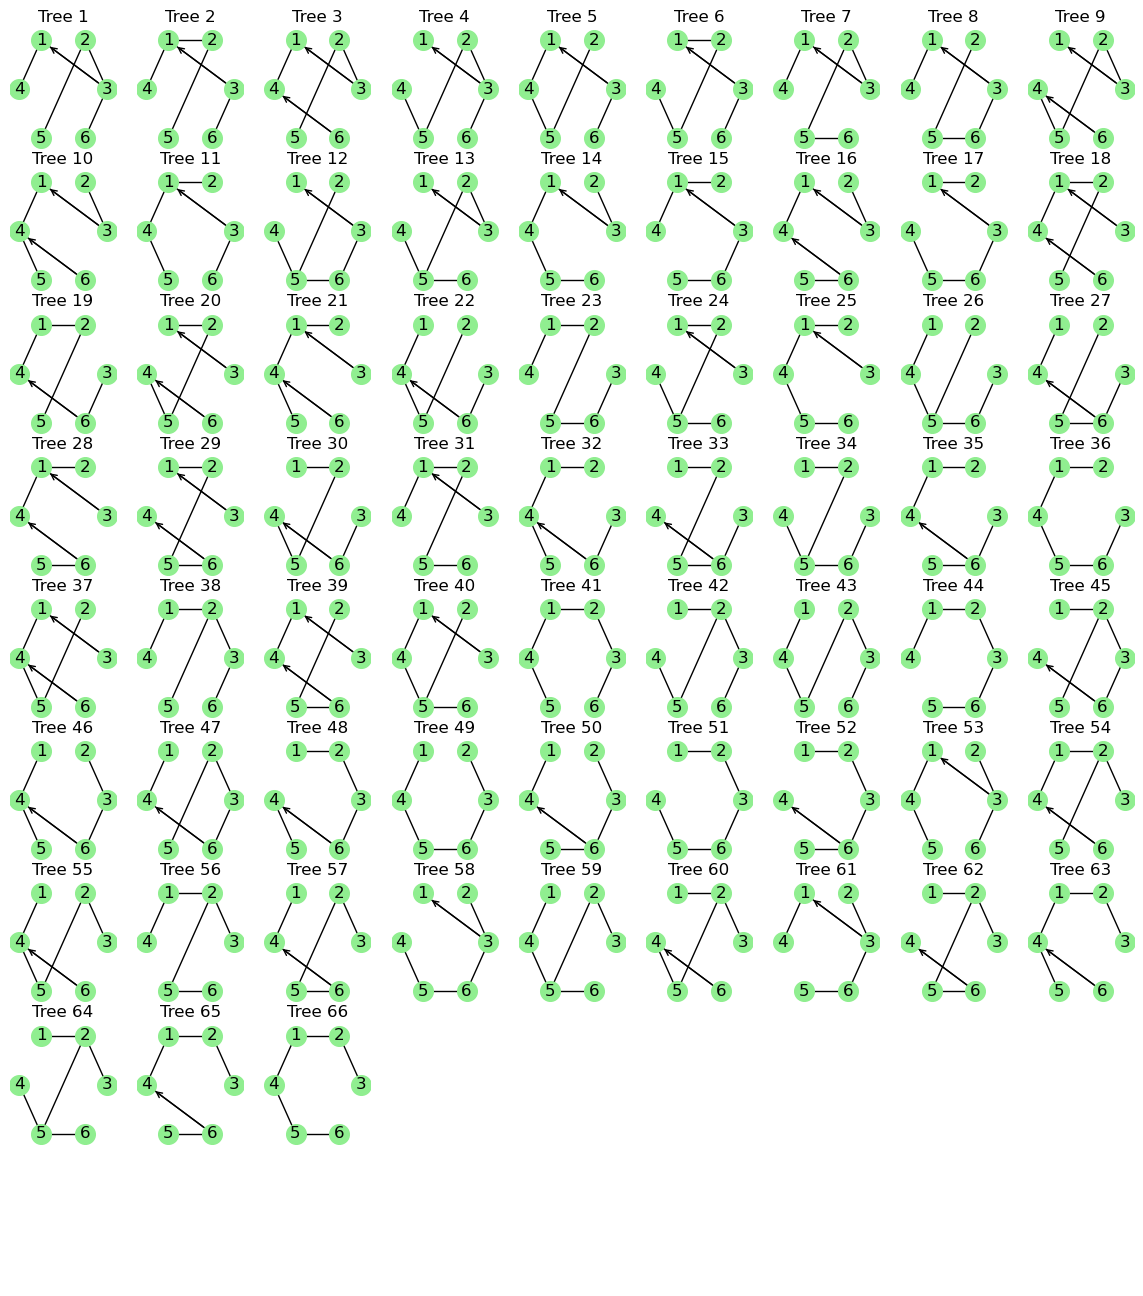

In [5]:
from dynamic_catalysis_model import generate_spanning_trees
G = nx.Graph()
G.add_nodes_from([2, 1, 0, 3, 4, 5])
G.add_edges_from([(0, 1), (1, 2), (0,2), (3,4), (4,5), (3,5), (0,3), (1,4), (2,5)])
fig, axs = plt.subplots(9, 9, figsize=(1.8125 * 8, 1.8125 * 9))
pos = nx.circular_layout(G)

absorption_edge_1 = (2,0)
absorption_edge_2 = (5,3)
spanning_trees = generate_spanning_trees(G, absorption_edge_1, absorption_edge_2)
for i, g in enumerate(spanning_trees):
    x_ax = i // 9
    y_ax = i % 9
    if (0,2) in g.edges or (2,0) in g.edges :
        axs[x_ax][y_ax].annotate('', xy=np.array(pos[0]) + 0.1 * (np.array(pos[2]) - np.array(pos[0])), xytext=np.array(pos[2]) - 0.1 * (np.array(pos[2]) - np.array(pos[0])), \
                                 arrowprops=dict(arrowstyle='->'))
    if (3,5) in g.edges or (5,3) in g.edges:
        axs[x_ax][y_ax].annotate('', xy=np.array(pos[3]) + 0.1 * (np.array(pos[5]) - np.array(pos[3])), xytext=np.array(pos[5]) - 0.1 * (np.array(pos[5]) - np.array(pos[3])), \
                                 arrowprops=dict(arrowstyle='->'))
    axs[x_ax][y_ax].set_title(f"Tree {i + 1}")
    nx.draw(g, pos, labels = {n: n + 1 for n in G}, node_color='lightgreen', node_size=200, ax=axs[x_ax][y_ax])

for i in range(9):
    for j in range(9):
        axs[i][j].axis('off')
plt.show()

# Part 2: steady-state

In [3]:
from six_state_model import dynamic_steady_state_diagram
import networkx as nx
import numpy as np
oscMidpoint = 0
k_bT = 1
dG_1 = 2
dG_2 = 2
epsilon = 0

alpha_21 = 1
alpha_32 = 1

alpha_54 = 1 
alpha_65 = 1 
gamma = 20
N = 6
G = nx.Graph()
G.add_nodes_from([2, 1, 0, 3, 4, 5])
G.add_edges_from([(0, 1), (1, 2), (0,2), (3,4), (4,5), (3,5), (0,3), (1,4), (2,5)])
node_indices = list(range(N))
spanTreesGraph = [i for i in nx.SpanningTreeIterator(G)]
epsilon_list = np.linspace(-5,5,50)
J_tot_list = []
J_limit_1_list = []
J_limit_2_list = []

for epsilon in epsilon_list:
    epsilon_1 = epsilon
    epsilon_2 = epsilon
    alpha_14 = 1e-11
    alpha_41 = 1e-11
    # alpha_41 = alpha_14
    J_1, J_2, J_3, J_4, J_5, J_6, J_7, J_8, J_9, J_10, J_11, J_f1, J_f2, J_f3 = dynamic_steady_state_diagram(epsilon_1, epsilon_2, alpha_21, alpha_32, gamma, gamma, alpha_14, alpha_41, dG_1=dG_1, dG_2=dG_2, k_bT=1, spanTreesGraph=spanTreesGraph)
    J_1 = float(J_1)
    J_2 = float(J_2)
    J_3 = float(J_3)
    J_4 = float(J_4)
    J_5 = float(J_5)
    J_6 = float(J_6)
    J_7 = float(J_7)
    J_8 = float(J_8)
    J_9 = float(J_9)
    J_10 = float(J_10)
    J_11 = float(J_11)
    J_f1 = float(J_f1)
    J_f2 = float(J_f2)
    J_f3 = float(J_f3)
    
    J_tot = np.abs(J_4) + np.abs(J_5) + np.abs(J_6) + np.abs(J_7) + np.abs(J_8) + np.abs(J_9) + np.abs(J_10) + np.abs(J_11)
    J_tot_list.append(J_tot)

    J_1, J_2, J_3, J_4, J_5, J_6, J_7, J_8, J_9, J_10, J_11, J_f1, J_f2, J_f3 = dynamic_steady_state_diagram(epsilon_1, epsilon_2, alpha_21, alpha_32, gamma, gamma, alpha_14, alpha_41, dG_1=100, dG_2=dG_2, k_bT=1, spanTreesGraph=spanTreesGraph)
    J_1 = float(J_1)
    J_2 = float(J_2)
    J_3 = float(J_3)
    J_4 = float(J_4)
    J_5 = float(J_5)
    J_6 = float(J_6)
    J_7 = float(J_7)
    J_8 = float(J_8)
    J_9 = float(J_9)
    J_10 = float(J_10)
    J_11 = float(J_11)
    J_f1 = float(J_f1)
    J_f2 = float(J_f2)
    J_f3 = float(J_f3)
    J_tot = np.abs(J_4) + np.abs(J_5) + np.abs(J_6) + np.abs(J_7) + np.abs(J_8) + np.abs(J_9) + np.abs(J_10) + np.abs(J_11)
    J_limit_1_list.append(J_tot)

    J_1, J_2, J_3, J_4, J_5, J_6, J_7, J_8, J_9, J_10, J_11, J_f1, J_f2, J_f3 = dynamic_steady_state_diagram(epsilon_1, epsilon_2, alpha_21, alpha_32, gamma, gamma, alpha_14, alpha_41, dG_1=dG_1, dG_2=100, k_bT=1, spanTreesGraph=spanTreesGraph)
    J_1 = float(J_1)
    J_2 = float(J_2)
    J_3 = float(J_3)
    J_4 = float(J_4)
    J_5 = float(J_5)
    J_6 = float(J_6)
    J_7 = float(J_7)
    J_8 = float(J_8)
    J_9 = float(J_9)
    J_10 = float(J_10)
    J_11 = float(J_11)
    J_f1 = float(J_f1)
    J_f2 = float(J_f2)
    J_f3 = float(J_f3)
    J_tot = np.abs(J_4) + np.abs(J_5) + np.abs(J_6) + np.abs(J_7) + np.abs(J_8) + np.abs(J_9) + np.abs(J_10) + np.abs(J_11)
    J_limit_2_list.append(J_tot)







<>:11: SyntaxWarning: invalid escape sequence '\e'
<>:12: SyntaxWarning: invalid escape sequence '\ '
<>:11: SyntaxWarning: invalid escape sequence '\e'
<>:12: SyntaxWarning: invalid escape sequence '\ '
/var/folders/98/m6nhh0gx4nsgd2v7r1tl07cc0000gn/T/ipykernel_62068/3049595576.py:11: SyntaxWarning: invalid escape sequence '\e'
  plt.xlabel('$\epsilon \ [k_B T]$', fontsize=9, fontdict={'family': 'sans-serif'})
/var/folders/98/m6nhh0gx4nsgd2v7r1tl07cc0000gn/T/ipykernel_62068/3049595576.py:12: SyntaxWarning: invalid escape sequence '\ '
  plt.ylabel('$J_{tot} \ [s^{-1}]$', fontsize=9, fontdict={'family': 'sans-serif'})
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.


findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Font family ['sans-serif'] not found. Falling back to DejaVu Sans.
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not fou

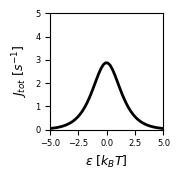

In [4]:
import matplotlib.pyplot as plt
plt.figure(figsize=(1.9,1.9))

# s3 = figure(title="Flux", x_range=(-5, 5), y_range=(0,5), tools="", toolbar_location=None, width=170, height=170)
plt.rcParams['font.sans-serif'] = ['Lucida Sans']
plt.xlim(-5, 5)
plt.ylim(0, 5)
plt.plot(epsilon_list, J_tot_list, color='black', label='Total Flux', linewidth=2)
# plt.plot(epsilon_list, J_limit_1_list, color='#92278f', linestyle='dashdot', label='Limit 1', linewidth=2)
# plt.plot(epsilon_list, J_limit_2_list, color='#f7941d', linestyle='dashdot', label='Limit 2', linewidth=2)
plt.xlabel('$\epsilon \ [k_B T]$', fontsize=9, fontdict={'family': 'sans-serif'})
plt.ylabel('$J_{tot} \ [s^{-1}]$', fontsize=9, fontdict={'family': 'sans-serif'})
plt.xticks([-5, -2.5, 0, 2.5, 5], fontsize=6)
plt.yticks([i for i in range(0, 6)], fontsize=6)
ax = plt.gca()
for tick in ax.get_xticklabels():
    tick.set_fontname("Lucida Sans")
for tick in ax.get_yticklabels():
    tick.set_fontname("Lucida Sans")
# idx = np.argmin(np.abs(epsilon_list - epsilon_list[np.where(np.array(J_tot_list) == np.max(J_tot_list))[0][0]]))
# plt.scatter(epsilon_list[idx], J_tot_list[idx], color='red', s=50, label='Current Point')
# plt.legend()
plt.tight_layout()

In [7]:
from dynamic_catalysis_model import cycle_flux_six_states, root_tree_weights, map_graph_weights_six_states
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
import mpmath
G = nx.Graph()
G.add_nodes_from([2, 1, 0, 3, 4, 5])
G.add_edges_from([(0, 1), (1, 2), (0,2), (3,4), (4,5), (3,5), (0,3), (1,4), (2,5)])
# oscMidpoint = mpmath.mpf(0)
k_bT = mpmath.mpf(1)
dG_1 = mpmath.mpf(2)
dG_2 = mpmath.mpf(2)
epsilon = mpmath.mpf(0)

alpha_21 = mpmath.mpf(1)
alpha_32 = mpmath.mpf(1)

alpha_54 = mpmath.mpf(1) 
alpha_65 = mpmath.mpf(1) 
gamma = mpmath.mpf(20)
N = 6
node_indices = list(range(N))

epsilon_list = np.linspace(-5,5,50)
J_tot_list_cycle = []
J_limit_1_list = []
J_limit_2_list = []

# epsilon_list=[0]
for epsilon in epsilon_list:
    epsilon_1 = epsilon
    epsilon_2 = epsilon
    alpha_14 = 1e-11
    alpha_41 = 1e-11
    # alpha_41 = alpha_14
    cycle_4 = [3,4,5]
    cycle_5 = [0,1,2]
    cycle_6 = [0,3,4,5,2]
    cycle_7 = [3,0,1,2,5]
    cycle_8 = [3,0,1,4,5]
    cycle_9 = [0,3,4,1,2]
    cycle_10 = [0,1,4,5,2]
    cycle_11 = [3,4,1,2,5]
    turnover_cycles = [cycle_4, cycle_5, cycle_6, cycle_7, cycle_8, cycle_9, cycle_10, cycle_11]
    # turnover_cycles = [cycle_4]
    J_tot, J_f = cycle_flux_six_states(turnover_cycles, [], G, (2,0), (5,3), alpha_32=alpha_32, \
                                              alpha_21=alpha_21, alpha_65=alpha_65, alpha_54=alpha_54,\
                                              alpha_14=alpha_14, alpha_41=alpha_41, dG_1=dG_1, dG_2=dG_2,\
                                              gamma=gamma, epsilon_1=epsilon_1, epsilon_2=epsilon_2, k_bT=k_bT)
    # alpha_12 = alpha_21 * mpmath.exp((dG_1 + epsilon_1) / k_bT)
    # alpha_23 = alpha_32 * mpmath.exp((dG_2 - epsilon_1)/ k_bT)

    # alpha_54 = alpha_21
    # alpha_65 = alpha_32
    # alpha_45 = alpha_54 * mpmath.exp((dG_1 + epsilon_2) / k_bT)
    # alpha_56 = alpha_65 * mpmath.exp((dG_2 - epsilon_2) / k_bT)
    # alpha_25 = alpha_14
    # alpha_52 = alpha_41
    # alpha_36 = alpha_14
    # alpha_63 = alpha_41
    # gamma_1 = gamma
    # gamma_2 = gamma
    # sigma_4 = alpha_14 * alpha_25 * alpha_36 + alpha_21 * alpha_14 * alpha_36 + \
    #     alpha_14 * alpha_23 * alpha_36 + alpha_12 * alpha_23 * alpha_36 + \
    #     alpha_32 * alpha_21 * alpha_14 + alpha_12 * alpha_32 * alpha_25 + \
    #     gamma_1 * alpha_21 * alpha_14 + gamma_1 * alpha_12 * alpha_25 + \
    #     gamma_1 * alpha_14 * alpha_25 + alpha_23 * gamma_1 * alpha_14 + \
    #     alpha_12 * alpha_25 * alpha_36 + alpha_32 * alpha_25 * alpha_14
    # Pi_4_minus = alpha_45 * alpha_56 * gamma_2
    # spanTreesGraph = [i for i in nx.SpanningTreeIterator(G)]
    # weights = map_graph_weights_six_states(alpha_32, alpha_21, alpha_65, alpha_54,\
    #                     alpha_14, alpha_41, dG_1, dG_2,\
    #                     gamma, epsilon_1, epsilon_2, k_bT)
    # tree_weights = [root_tree_weights(spanTreesGraph[i], weights, (2,0), (5,3), nodes=None) for i in range(len(spanTreesGraph))]
    # sigma = np.sum(tree_weights) 
    # J_4 = Pi_4_minus * sigma_4 / sigma  
    J_tot_list_cycle.append(J_tot)
    # break




<>:12: SyntaxWarning: invalid escape sequence '\e'
<>:13: SyntaxWarning: invalid escape sequence '\ '
<>:12: SyntaxWarning: invalid escape sequence '\e'
<>:13: SyntaxWarning: invalid escape sequence '\ '
/var/folders/98/m6nhh0gx4nsgd2v7r1tl07cc0000gn/T/ipykernel_62068/663729672.py:12: SyntaxWarning: invalid escape sequence '\e'
  plt.xlabel('$\epsilon \ [k_B T]$', fontsize=9, fontdict={'family': 'sans-serif'})
/var/folders/98/m6nhh0gx4nsgd2v7r1tl07cc0000gn/T/ipykernel_62068/663729672.py:13: SyntaxWarning: invalid escape sequence '\ '
  plt.ylabel('$J_{tot} \ [s^{-1}]$', fontsize=9, fontdict={'family': 'sans-serif'})
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Font family 'Lucida Sans' not found.
findfont: Generic family 'sans-serif' not found because none of the following families were fo

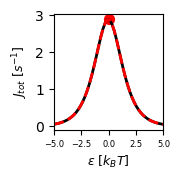

In [8]:
import matplotlib.pyplot as plt
from dynamic_catalysis_model import max_rate_six_states, osc_midpoint_six_states
plt.figure(figsize=(1.9,1.9))
# s3 = figure(title="Flux", x_range=(-5, 5), y_range=(0,5), tools="", toolbar_location=None, width=170, height=170)
plt.rcParams['font.sans-serif'] = ['Lucida Sans']
plt.xlim(-5, 5)
# plt.ylim(0, 5)
plt.plot(epsilon_list, J_tot_list_cycle, color='black', label='Total Flux', linewidth=2)
plt.plot(epsilon_list, J_tot_list, color='red', label='hard-coded methods', linewidth=2, linestyle='dashed')
# plt.plot(epsilon_list, J_limit_1_list, color='#92278f', linestyle='dashdot', label='Limit 1', linewidth=2)
# plt.plot(epsilon_list, J_limit_2_list, color='#f7941d', linestyle='dashdot', label='Limit 2', linewidth=2)
plt.xlabel('$\epsilon \ [k_B T]$', fontsize=9, fontdict={'family': 'sans-serif'})
plt.ylabel('$J_{tot} \ [s^{-1}]$', fontsize=9, fontdict={'family': 'sans-serif'})
plt.xticks([-5, -2.5, 0, 2.5, 5], fontsize=6)
# plt.yticks([i for i in range(0, 6)], fontsize=6)
ax = plt.gca()
for tick in ax.get_xticklabels():
    tick.set_fontname("Lucida Sans")
for tick in ax.get_yticklabels():
    tick.set_fontname("Lucida Sans")
midpoint = osc_midpoint_six_states(alpha_32, alpha_21, alpha_65, alpha_54,\
                        alpha_14, alpha_41, dG_1, dG_2,\
                        gamma, epsilon_1, epsilon_2, k_bT)

J_max = max_rate_six_states(alpha_32, alpha_21, alpha_65, alpha_54,\
                        alpha_14, alpha_41, dG_1, dG_2,\
                        gamma, epsilon_1, epsilon_2, k_bT)

plt.scatter(midpoint, J_max, color='red', s=50, label='Current Point')
# plt.legend()
plt.tight_layout()

In [11]:
from dynamic_catalysis_model import cycle_inflows, map_graph_weights_six_states
weights = map_graph_weights_six_states(alpha_32, alpha_21, alpha_65, alpha_54,\
                        alpha_14, alpha_41, dG_1, dG_2,\
                        gamma, epsilon_1, epsilon_2, k_bT)
trees = cycle_inflows(cycle_4, G, weights, (2,0), (5,3))

5.45981500331442e-10
4.97870683678639e-24
1.09663315842846e-19
9.999999999999999e-34
1.0e-22
4.97870683678639e-13
1.0e-22
1.0e-11
2.19914827347146e-10
4.38653263371383e-7
6.0e-21
4.09957413673573e-10


findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
findfont: Generic family 'sans-serif' not found because none of the following families were found: Lucida Sans
f

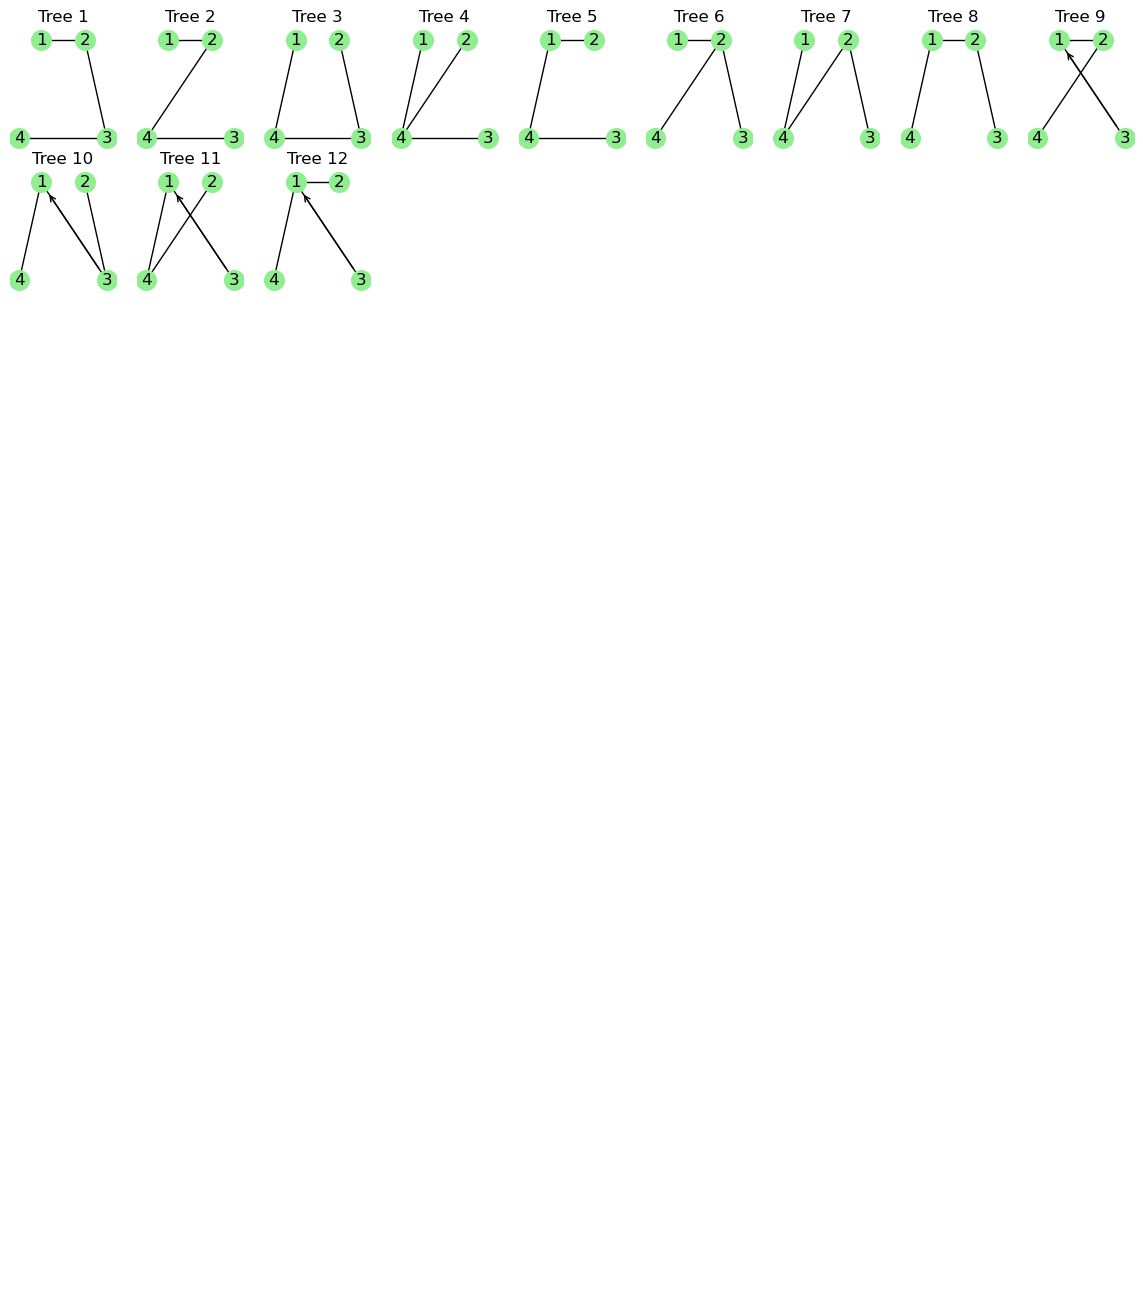

In [12]:
G = nx.Graph()
G.add_nodes_from([2, 1, 0, 3, 4, 5])
G.add_edges_from([(0, 1), (1, 2), (0,2), (3,4), (4,5), (3,5), (0,3), (1,4), (2,5)])
fig, axs = plt.subplots(9, 9, figsize=(1.8125 * 8, 1.8125 * 9))
pos = nx.circular_layout(G)

absorption_edge_1 = (2,0)
absorption_edge_2 = (5,3)
for i, g in enumerate(trees):
    x_ax = i // 9
    y_ax = i % 9
    if (0,2) in g.edges or (2,0) in g.edges :
        axs[x_ax][y_ax].annotate('', xy=np.array(pos[0]) + 0.1 * (np.array(pos[2]) - np.array(pos[0])), xytext=np.array(pos[2]) - 0.1 * (np.array(pos[2]) - np.array(pos[0])), \
                                 arrowprops=dict(arrowstyle='->'))
    if (3,5) in g.edges or (5,3) in g.edges:
        axs[x_ax][y_ax].annotate('', xy=np.array(pos[3]) + 0.1 * (np.array(pos[5]) - np.array(pos[3])), xytext=np.array(pos[5]) - 0.1 * (np.array(pos[5]) - np.array(pos[3])), \
                                 arrowprops=dict(arrowstyle='->'))
    axs[x_ax][y_ax].set_title(f"Tree {i + 1}")
    nx.draw(g, pos, labels = {n: n + 1 for n in G}, node_color='lightgreen', node_size=200, ax=axs[x_ax][y_ax])

for i in range(9):
    for j in range(9):
        axs[i][j].axis('off')
plt.show()

In [15]:
20 * 1e-11 * np.exp(2)

np.float64(1.47781121978613e-09)

# Part 3: dynamic steady-state heatmap

In [7]:
import matplotlib.pyplot as plt
import matplotlib.colors
import numpy as np
from matplotlib.colors import LinearSegmentedColormap, LogNorm, Normalize
from dynamic_catalysis_model import max_rate_six_states, cycle_flux_six_states, osc_midpoint_six_states, map_graph_weights_six_states

import mpmath
import numpy as np
import bokeh.layouts
import bokeh.models
import bokeh.plotting

from IPython.display import display
from jupyter_bokeh.widgets import BokehModel
from bokeh.io import output_notebook, export_svg, export_png
from bokeh.plotting import figure
from ipywidgets import interact

from bokeh.io import output_file, show, export_svgs
from bokeh.layouts import row
from bokeh.models import Ellipse, GraphRenderer, StaticLayoutProvider, Circle
from bokeh.palettes import Spectral6, Reds3, brewer
from bokeh.plotting import figure
from IPython.display import display
from bokeh.models import (Arrow, Label, NormalHead, OpenHead,
                          Plot, Range1d, TeeHead, VeeHead)
from bokeh.models import MathML
import pickle as pkl
import networkx as nx
output_notebook()


def heatmap(F1, F2, alpha_21, alpha_32, gamma, dG_1, dG_2, oscMidpoint, amplitude):
    turnover_fold_increase = np.zeros(F1.shape)
    for i in range(F1.shape[0]):
        for j in range(F1.shape[1]):

            epsilon_1 = float(oscMidpoint + amplitude)
            epsilon_2 = float(oscMidpoint - amplitude)

            alpha_14 = F1[i, j]
            alpha_41 = F2[i, j] 

            J_turnover, J_futile = cycle_flux_six_states(turnover_cycles, [], G, (2,0), (5,3), alpha_32=alpha_32, alpha_21=alpha_21, alpha_65=alpha_65, alpha_54=alpha_54,\
                        alpha_14=alpha_14, alpha_41=alpha_41, dG_1=dG_1, dG_2=dG_2,\
                        gamma=gamma, epsilon_1=epsilon_1, epsilon_2=epsilon_2, k_bT=k_bT)
        
            turnover_fold_increase[i, j] = J_turnover
    return turnover_fold_increase

Loading BokehJS ...

In [10]:



class MidPointLogNorm(LogNorm):
    def __init__(self, vmin=None, vmax=None, midpoint=None, clip=False):
        LogNorm.__init__(self,vmin=vmin, vmax=vmax, clip=clip)
        self.midpoint=midpoint
    def __call__(self, value, clip=None):
        # I'm ignoring masked values and all kinds of edge cases to make a
        # simple example...
        x, y = [np.log(self.vmin), np.log(self.midpoint), np.log(self.vmax)], [0, 0.5, 1]
        return np.ma.masked_array(np.interp(np.log(value), x, y))

gamma=20000
dG_1 = 2
dG_2 = 2
alpha_21 = 1
alpha_32 = 1
alpha_65=1
alpha_54=1
k_bT=1
max_frequency=100
n_points=20

frequencies_1 = np.linspace(1e-5, max_frequency, n_points)
frequencies_2 = np.linspace(1e-5, max_frequency, n_points)
amplitude = 2
cycle_4 = [3,4,5]
cycle_5 = [0,1,2]
cycle_6 = [0,3,4,5,2]
cycle_7 = [3,0,1,2,5]
cycle_8 = [3,0,1,4,5]
cycle_9 = [0,3,4,1,2]
cycle_10 = [0,1,4,5,2]
cycle_11 = [3,4,1,2,5]
G = nx.Graph()
G.add_nodes_from([2, 1, 0, 3, 4, 5])
G.add_edges_from([(0, 1), (1, 2), (0,2), (3,4), (4,5), (3,5), (0,3), (1,4), (2,5)])
turnover_cycles = [cycle_4, cycle_5, cycle_6, cycle_7, cycle_8, cycle_9, cycle_10, cycle_11]

palette = brewer['PuOr'][11][::-1]
palette = bokeh.palettes.interp_palette(palette, 400)

F1, F2 = np.meshgrid(frequencies_1, frequencies_2)
oscMidpoint = osc_midpoint_six_states(alpha_32, alpha_21, alpha_65, alpha_54, None, None, dG_1, dG_2, gamma, None, None, k_bT)
turnover_fold_increase = heatmap(F1, F2, alpha_21, alpha_32, gamma, dG_1, dG_2, oscMidpoint, amplitude)
bound = np.min([np.abs(np.max(np.log10(turnover_fold_increase))), np.abs(np.min(np.log10(turnover_fold_increase)))])

cmap = LinearSegmentedColormap.from_list('mycmap', palette)
plt.figure(figsize=(2.4, 1.9))
plt.imshow(turnover_fold_increase, extent=(1e-5, max_frequency, 1e-5, max_frequency), norm=MidPointLogNorm(vmin=np.min(turnover_fold_increase), vmax=np.max(turnover_fold_increase), midpoint=1), origin='lower', aspect='auto', cmap=cmap)
plt.xlabel(r'$w_{I,II}\ [s^{-1}]$', fontsize=9, fontdict={'fontname': 'Lucida Sans'})
plt.ylabel(r'$w_{II,I}\ [s^{-1}]$', fontsize=9, fontdict={'fontname': 'Lucida Sans'})
plt.xticks([20, 40, 60, 80, 100], fontsize=6)
plt.yticks([20, 40, 60, 80, 100], fontsize=6)
ax = plt.gca()
for tick in ax.get_xticklabels():
    tick.set_fontname("Lucida Sans")
for tick in ax.get_yticklabels():
    tick.set_fontname("Lucida Sans")
cbar = plt.colorbar(label='$J_{tot}$ Fold Change')
cbar.set_label('$J_{tot}$ Fold Change', fontdict={'fontname': 'Lucida Sans'}, fontsize=9)
cbar.set_ticks([0.5, 1, 1.5, 2, 3])
cbar.set_ticklabels([0.5, 1, 1.5, 2, 3], fontdict={'fontname': 'Lucida Sans'}, fontsize=6)
plt.tight_layout()

2.4999375020885306e-05


KeyboardInterrupt: 

# Part 4: phase diagram